# Stock price forecasting using LOB

Before start, we need to test some libraries in order to build a reasonable dataset for the neural network architecture. Test will be focused on libraries for crypto market data and stock market data. For more corporate indices (bank indices) maybe there are other libraries to test in a second moment.

### Import modules

In [1]:
import time 
import pandas
import random
import json, argparse

# ML
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from plotly.subplots import make_subplots
from plotly import graph_objects as go
from sklearn import preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, roc_auc_score, mean_absolute_percentage_error, root_mean_squared_error

# pytorch
import torch.nn as nn
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import torch.utils

# software modules
import models_regression as Models
import utils
import dataset as Dataset

### Load LOB data

In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print('Using device:', device)

Using device: cuda:0


In [3]:
dataset = pd.read_parquet('/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/Data/FI-2010-Cleaned/NoAuction/Zscore/WRT1V.parquet')
dataset = dataset.drop(['Label_10', 'Label_20', 'Label_30', 'Label_50', 'Label_100', 'Day'], axis=1)
dataset['mid_price'] = (dataset['P_Ask_1'] + dataset['P_Bid_1']) / 2
dataset = dataset.astype(float)
dataset = dataset.head(100000)
display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price
0,1.242406,-0.611621,1.240199,-0.446819,1.241779,-0.663252,1.240732,-0.512393,1.241182,-0.770717,...,-0.349285,1.238846,-0.418570,1.243297,-0.499588,1.236425,-0.444236,1.243820,-0.278126,1.241302
1,1.241385,-0.678429,1.240199,-0.555044,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
2,1.241385,-0.678429,1.240199,-0.465970,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
3,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
4,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,1.326816,-0.316930,1.325949,-0.007630,1.326211,-0.449060,1.325580,-0.646518,1.325653,-0.796965,...,-0.582431,1.325328,-0.458368,1.322656,-0.206374,1.323444,-0.397135,1.324398,-0.483234,1.326383
99996,1.326816,-0.316930,1.325949,0.115155,1.326211,-0.564407,1.325580,-0.646518,1.325653,-0.796965,...,-0.590642,1.325328,-0.458368,1.326670,-0.518637,1.323444,-0.397135,1.325403,-0.230280,1.326383
99997,1.326816,-0.316930,1.325949,0.176547,1.326211,-0.564407,1.325580,-0.646518,1.325653,-0.796965,...,-0.590642,1.325328,-0.458368,1.326670,-0.518637,1.323444,-0.397135,1.325403,-0.230280,1.326383
99998,1.326816,-0.316930,1.325949,0.176547,1.326211,-0.564407,1.325580,-0.646518,1.325653,-0.796965,...,-0.582431,1.325328,-0.458368,1.322656,-0.206374,1.323444,-0.397135,1.324398,-0.483234,1.326383


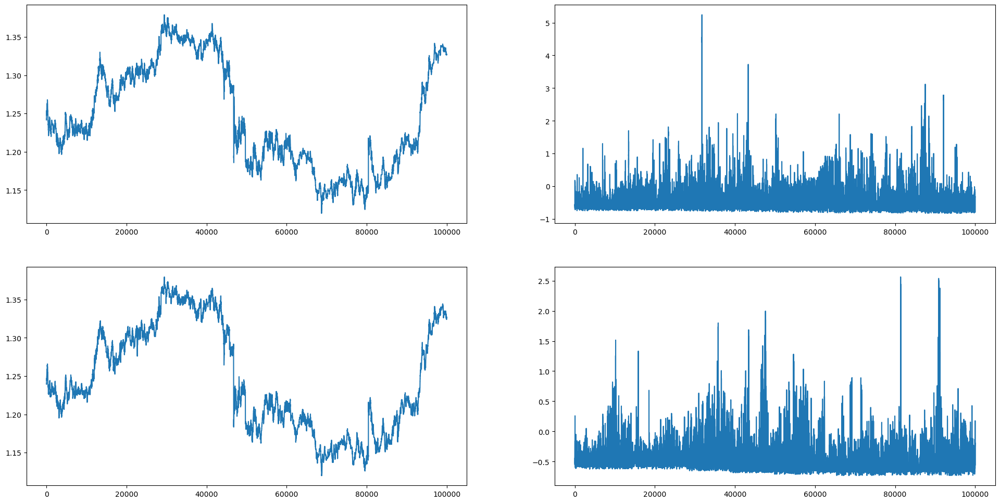

In [4]:
_, axs = plt.subplots(2, 2, figsize=(24,12))
axs[0,0].plot(dataset['P_Ask_1'])
axs[0,1].plot(dataset['V_Ask_1'])
axs[1,0].plot(dataset['P_Bid_1'])
axs[1,1].plot(dataset['V_Bid_1'])
plt.show()

## Single Horizon Regression:

Create the effective time-series dataset, and the batch-iterators to process tensors using the sliding window procedure

In [5]:
target_col = 'mid_price'
target_cols = []
shifts = [ 10 ]

for shift in shifts:
    colname = f'Target_{shift}'
    target_cols.append(colname)
    dataset[colname] = dataset[target_col].shift(-shift)
dataset.dropna(inplace=True)

display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price,Target_10
0,1.242406,-0.611621,1.240199,-0.446819,1.241779,-0.663252,1.240732,-0.512393,1.241182,-0.770717,...,1.238846,-0.418570,1.243297,-0.499588,1.236425,-0.444236,1.243820,-0.278126,1.241302,1.241301
1,1.241385,-0.678429,1.240199,-0.555044,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792,1.241813
2,1.241385,-0.678429,1.240199,-0.465970,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792,1.241813
3,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792,1.241813
4,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792,1.241813
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99985,1.326816,-0.581266,1.326950,-0.563844,1.326211,-0.564407,1.327582,-0.427819,1.325653,-0.796965,...,1.325328,-0.458368,1.324663,-0.518637,1.323444,-0.397135,1.325403,-0.230280,1.326883,1.326383
99986,1.326816,-0.581266,1.325949,-0.250129,1.326211,-0.564407,1.325580,-0.646518,1.325653,-0.796965,...,1.325328,-0.458368,1.324663,-0.518637,1.323444,-0.397135,1.325403,-0.230280,1.326383,1.326383
99987,1.326816,-0.792588,1.325949,-0.250129,1.326211,-0.564407,1.325580,-0.646518,1.325653,-0.796965,...,1.325328,-0.458368,1.324663,-0.518637,1.323444,-0.397135,1.325403,-0.230280,1.326383,1.326383
99988,1.327815,-0.313248,1.325949,0.053763,1.327210,-0.693019,1.325580,-0.646518,1.327650,-0.147729,...,1.326325,-0.400868,1.322656,-0.206374,1.324440,-0.218239,1.324398,-0.483234,1.326882,1.326383


In [6]:
# Split the dataframe into train, validation and test
dataset_train, dataset_val, dataset_test = utils.DataTools.train_val_test_split(dataset)

# Standardize the data
#scaler = preprocessing.StandardScaler()
#scaler.fit(dataset_train)

#dataset_train[dataset_train.columns] = scaler.transform(dataset_train)
#dataset_val[dataset_val.columns] = scaler.transform(dataset_val)
#dataset_test[dataset_test.columns] = scaler.transform(dataset_test)

means = dataset_train.mean(axis=0)
stds = dataset_train.std(axis=0)

means[-len(target_cols):] = means[target_cols]
stds[-len(target_cols):] = stds[target_cols]

dataset_train = ( dataset_train - means ) / stds
dataset_val = ( dataset_val - means ) / stds
dataset_test = ( dataset_test - means ) / stds

display(dataset_train)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price,Target_10
0,-0.307315,-0.526407,-0.341118,0.003650,-0.315905,-0.457705,-0.332309,0.032010,-0.324138,-0.477910,...,-0.340097,-0.611772,-0.294305,-0.654405,-0.370801,-0.784057,-0.289278,0.810160,-0.324371,-0.324085
1,-0.323455,-0.715304,-0.341118,-0.468857,-0.332034,-0.457705,-0.332309,-0.403619,-0.340270,-0.477910,...,-0.404618,-0.584430,-0.278324,0.388271,-0.419216,1.271839,-0.257368,-0.541026,-0.332404,-0.316040
2,-0.323455,-0.715304,-0.341118,-0.079963,-0.332034,-0.457705,-0.332309,-0.403619,-0.340270,-0.477910,...,-0.404618,-0.584430,-0.278324,0.388271,-0.419216,1.271839,-0.257368,-0.541026,-0.332404,-0.316040
3,-0.323455,-0.715304,-0.341118,-0.406634,-0.332034,-0.457705,-0.332309,0.032010,-0.340270,-0.477910,...,-0.404618,-0.584430,-0.278324,0.388271,-0.419216,1.271839,-0.257368,-0.541026,-0.332404,-0.316040
4,-0.323455,-0.715304,-0.341118,-0.406634,-0.332034,-0.457705,-0.332309,0.032010,-0.340270,-0.477910,...,-0.404618,-0.584430,-0.278324,0.388271,-0.419216,1.271839,-0.257368,-0.541026,-0.332404,-0.316040
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69988,-1.854454,-0.576742,-1.859765,-0.292893,-1.862346,-0.654563,-1.850642,0.264430,-1.854742,-0.027349,...,-1.905480,-0.845793,-1.848257,-0.453077,-1.929467,-0.635627,-1.868771,-1.007627,-1.857542,-1.888407
69989,-1.854454,-0.576742,-1.859765,-0.292893,-1.862346,-0.654563,-1.850642,0.264430,-1.854742,-0.027349,...,-1.905480,-0.845793,-1.848257,-0.453077,-1.929467,-0.635627,-1.868771,-1.007627,-1.857542,-1.872639
69990,-1.854454,-0.576742,-1.859765,-0.292893,-1.862346,-0.654563,-1.850642,0.264430,-1.854742,-0.027349,...,-1.905480,-0.845793,-1.848257,-0.453077,-1.929467,-0.635627,-1.868771,-1.007627,-1.857542,-1.872639
69991,-1.854454,-0.576742,-1.859765,-0.292893,-1.862346,-0.654563,-1.850642,0.264430,-1.854742,-0.027349,...,-1.905480,-0.845793,-1.848257,-0.453077,-1.929467,-0.635627,-1.868771,-1.007627,-1.857542,-1.864754


In [7]:
# Split covariates and response variables
X_train, y_train = utils.DataTools.split_x_y(dataset_train, target_cols)
X_val, y_val = utils.DataTools.split_x_y(dataset_val, target_cols)
X_test, y_test = utils.DataTools.split_x_y(dataset_test, target_cols)

# Convert to pytorch tensors
X_train, X_val, X_test = utils.DataTools.numpy_to_tensor( X_train, X_val, X_test, dtype=torch.float32 )
y_train, y_val, y_test = utils.DataTools.numpy_to_tensor( y_train, y_val, y_test, dtype=torch.float32 )

# Create Torch Dataset
lookback_period = 100
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)

# Create Torch DataLoader
batch_size = 32
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = batch_size,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = batch_size,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 128,
    shuffle = False
)

print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 69794 samples
Test dataset: 14800 samples


In [8]:
true = []
pred = []
for features, labels in dataloader_test:
    true.append(labels.numpy())
    #print(features.shape)
    for i in range(len(shifts)):
        pred.append(features[:, -1, 40].numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

print("dummy regressor: last value")
print()
for i in range(len(shifts)):
    print(shifts[i], "      ", "sMAPE: ", utils.Metrics.sMAPE(true[:, i], pred[:, i]), "   ", "RMSE: ", root_mean_squared_error(true[:, i], pred[:, i]))


true = []
pred = []
for features, labels in dataloader_test:
    true.append(labels.numpy())
    #print(features.shape)
    for i in range(len(shifts)):
        pred.append(np.mean(features[:, :, 40].numpy(), axis=1))

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

print()
print("dummy regressor: mean value")
print()
for i in range(len(shifts)):
    print(shifts[i], "      ", "sMAPE: ", utils.Metrics.sMAPE(true[:, i], pred[:, i]), "     ", "RMSE: ", root_mean_squared_error(true[:, i], pred[:, i]))

dummy regressor: last value

10        sMAPE:  5.565569177269936     RMSE:  0.023341948

dummy regressor: mean value

10        sMAPE:  12.76913732290268       RMSE:  0.06422597


### Baisc LSTM

In [9]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [10]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'hidden_layer_size': 64,
    'num_layers': 2,
    'output_size': y_train.shape[1],
    'dropout': 0.2
}
model = Models.LSTM1(**params).to(device)

# Define loss function and optimizer
learning_rate = 5*1e-4
epochs = 15
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = model.name + f'{shifts[0]}',
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/15 [00:00<?, ?it/s]

model saved
model saved
model saved
model saved


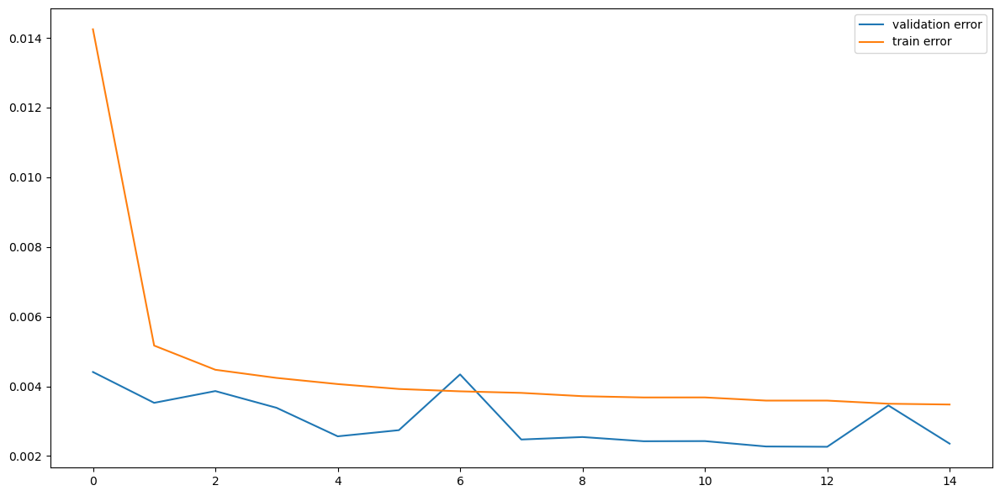

In [ ]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-{shifts[0]}-FI-reg-LOSS.pdf')
plt.show()

In [ ]:
# load the best model (or the final one)
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/LSTM1-FI-best_model.pt', weights_only=False)

true = []
pred = []

torch.cuda.empty_cache()
# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = best_model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

# Plot each dimension separately
fig = make_subplots(rows=y_train.shape[1], cols=1)
for i in range(y_train.shape[1]):
    fig.add_scatter(y=true[:,i], mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(y=pred[:,i], mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {[shifts[i] for i in range(y_train.shape[1])]}", xaxis_title = "Time", yaxis_title = "Price")
fig.write_html(f'./figures/{best_model.name}-FI-reg-pryce.html')
fig.show()

torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128, 1, 2])
torch.Size([128,

ValueError: cannot reshape array of size 14629 into shape (2)

In [ ]:
#np.save(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.npy', true, pred)
#torch.save(model.state_dict(), f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.pth')

In [ ]:
for i in range(len(shifts)):
    print(utils.Metrics.sMAPE(true[:, i], pred[:, i]))
    print(r2_score(true[:, i], pred[:, i]))
    print(root_mean_squared_error(true[:, i], pred[:, i]))
    print()

8.941837400197983
0.998161348464197
0.04005641



The simple LSTM model performs well, beating both the dummy regressors.

## Multi Horizon Regression:

In [3]:
dataset = pd.read_parquet('/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/Data/FI-2010-Cleaned/NoAuction/Zscore/WRT1V.parquet')
dataset = dataset.drop(['Label_10', 'Label_20', 'Label_30', 'Label_50', 'Label_100', 'Day'], axis=1)
dataset['mid_price'] = (dataset['P_Ask_1'] + dataset['P_Bid_1']) / 2
dataset = dataset.astype(float)
dataset = dataset.head(100000)
display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price
0,1.242406,-0.611621,1.240199,-0.446819,1.241779,-0.663252,1.240732,-0.512393,1.241182,-0.770717,...,-0.349285,1.238846,-0.418570,1.243297,-0.499588,1.236425,-0.444236,1.243820,-0.278126,1.241302
1,1.241385,-0.678429,1.240199,-0.555044,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
2,1.241385,-0.678429,1.240199,-0.465970,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
3,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
4,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,1.326816,-0.316930,1.325949,-0.007630,1.326211,-0.449060,1.325580,-0.646518,1.325653,-0.796965,...,-0.582431,1.325328,-0.458368,1.322656,-0.206374,1.323444,-0.397135,1.324398,-0.483234,1.326383
99996,1.326816,-0.316930,1.325949,0.115155,1.326211,-0.564407,1.325580,-0.646518,1.325653,-0.796965,...,-0.590642,1.325328,-0.458368,1.326670,-0.518637,1.323444,-0.397135,1.325403,-0.230280,1.326383
99997,1.326816,-0.316930,1.325949,0.176547,1.326211,-0.564407,1.325580,-0.646518,1.325653,-0.796965,...,-0.590642,1.325328,-0.458368,1.326670,-0.518637,1.323444,-0.397135,1.325403,-0.230280,1.326383
99998,1.326816,-0.316930,1.325949,0.176547,1.326211,-0.564407,1.325580,-0.646518,1.325653,-0.796965,...,-0.582431,1.325328,-0.458368,1.322656,-0.206374,1.323444,-0.397135,1.324398,-0.483234,1.326383


In [4]:
target_col = 'mid_price'
target_cols = []
shifts = [ 10, 20, 30, 50 ]

for shift in shifts:
    colname = f'Target_{shift}'
    target_cols.append(colname)
    dataset[colname] = dataset[target_col].shift(-shift)
dataset.dropna(inplace=True)

display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price,Target_10,Target_20,Target_30,Target_50
0,1.242406,-0.611621,1.240199,-0.446819,1.241779,-0.663252,1.240732,-0.512393,1.241182,-0.770717,...,-0.499588,1.236425,-0.444236,1.243820,-0.278126,1.241302,1.241301,1.244876,1.245899,1.248455
1,1.241385,-0.678429,1.240199,-0.555044,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792,1.241813,1.243855,1.246411,1.248455
2,1.241385,-0.678429,1.240199,-0.465970,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792,1.241813,1.243855,1.246411,1.247943
3,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792,1.241813,1.244877,1.246411,1.248455
4,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1.240792,1.241813,1.244877,1.246411,1.248455
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99945,1.326816,-0.166721,1.323948,-0.250129,1.326211,-0.564407,1.324579,-0.589179,1.325653,-0.796965,...,-0.536164,1.322448,-0.444968,1.316366,-0.306561,1.325382,1.325382,1.325382,1.325382,1.326383
99946,1.326816,-0.166721,1.323948,-0.250129,1.326211,-0.564407,1.324579,-0.589179,1.325653,-0.796965,...,-0.536164,1.322448,-0.444968,1.316366,-0.306561,1.325382,1.325382,1.325382,1.325382,1.326383
99947,1.326816,-0.166721,1.323948,-0.250129,1.326211,-0.564407,1.324579,-0.589179,1.325653,-0.796965,...,-0.536164,1.322448,-0.444968,1.316366,-0.306561,1.325382,1.325382,1.325382,1.325382,1.326383
99948,1.326816,-0.166721,1.323948,-0.250129,1.326211,-0.564407,1.324579,-0.589179,1.325653,-0.796965,...,-0.206374,1.322448,-0.444968,1.319378,-0.492045,1.325382,1.325382,1.325382,1.325382,1.326383


In [5]:
# Split the dataframe into train, validation and test
dataset_train, dataset_val, dataset_test = utils.DataTools.train_val_test_split(dataset)

# Standardize the data
#scaler = preprocessing.StandardScaler()
#scaler.fit(dataset_train)

#dataset_train[dataset_train.columns] = scaler.transform(dataset_train)
#dataset_val[dataset_val.columns] = scaler.transform(dataset_val)
#dataset_test[dataset_test.columns] = scaler.transform(dataset_test)

means = dataset_train.mean(axis=0)
stds = dataset_train.std  (axis=0)

means[-len(target_cols):] = means[target_cols]
stds[-len(target_cols):] = stds[target_cols]

dataset_train = ( dataset_train - means ) / stds
dataset_val = ( dataset_val - means ) / stds
dataset_test = ( dataset_test - means ) / stds

display(dataset_train)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price,Target_10,Target_20,Target_30,Target_50
0,-0.308219,-0.526534,-0.342036,0.003483,-0.316814,-0.457742,-0.333217,0.032109,-0.325050,-0.477706,...,-0.654436,-0.371768,-0.784013,-0.290149,0.809870,-0.325283,-0.324990,-0.268448,-0.252052,-0.211284
1,-0.324367,-0.715414,-0.342036,-0.468958,-0.332951,-0.457742,-0.333217,-0.403441,-0.341190,-0.477706,...,0.388122,-0.420209,1.272035,-0.258224,-0.541290,-0.333320,-0.316942,-0.284514,-0.244007,-0.211284
2,-0.324367,-0.715414,-0.342036,-0.080118,-0.332951,-0.457742,-0.333217,-0.403441,-0.341190,-0.477706,...,0.388122,-0.420209,1.272035,-0.258224,-0.541290,-0.333320,-0.316942,-0.284514,-0.244007,-0.219325
3,-0.324367,-0.715414,-0.342036,-0.406744,-0.332951,-0.457742,-0.333217,0.032109,-0.341190,-0.477706,...,0.388122,-0.420209,1.272035,-0.258224,-0.541290,-0.333320,-0.316942,-0.268420,-0.244007,-0.211284
4,-0.324367,-0.715414,-0.342036,-0.406744,-0.332951,-0.457742,-0.333217,0.032109,-0.341190,-0.477706,...,0.388122,-0.420209,1.272035,-0.258224,-0.541290,-0.333320,-0.316942,-0.268420,-0.244007,-0.211284
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69960,-1.919547,0.259077,-1.892896,-0.476571,-1.927403,-0.654619,-1.883781,0.643151,-1.935645,-0.647523,...,-1.097132,-1.994690,1.890540,-1.901760,-0.920434,-1.906589,-1.898001,-1.857867,-1.857190,-1.871570
69961,-1.919547,0.665861,-1.908623,0.855497,-1.927403,-0.654619,-1.899523,-0.321598,-1.935645,-0.647523,...,-1.005132,-1.962980,-0.679220,-1.948815,-1.007881,-1.914492,-1.890099,-1.857867,-1.857190,-1.871570
69962,-1.919547,-0.279912,-1.908623,0.855497,-1.927403,-0.654619,-1.899523,-0.321598,-1.935645,-0.647523,...,-1.097132,-1.962980,-0.679220,-1.901760,-0.920434,-1.914492,-1.890099,-1.857867,-1.857190,-1.871570
69963,-1.919547,-0.686696,-1.908623,0.855497,-1.927403,-0.654619,-1.899523,-0.321598,-1.935645,-0.647523,...,-1.097132,-1.962980,-0.679220,-1.901760,-0.920434,-1.914492,-1.890099,-1.857867,-1.857190,-1.871570


In [6]:
# Split covariates and response variables
X_train, y_train = utils.DataTools.split_x_y(dataset_train, target_cols)
X_val, y_val = utils.DataTools.split_x_y(dataset_val, target_cols)
X_test, y_test = utils.DataTools.split_x_y(dataset_test, target_cols)

# Convert to pytorch tensors
X_train, X_val, X_test = utils.DataTools.numpy_to_tensor( X_train, X_val, X_test, dtype=torch.float32 )
y_train, y_val, y_test = utils.DataTools.numpy_to_tensor( y_train, y_val, y_test, dtype=torch.float32 )

# Create Torch Dataset
lookback_period = 100
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)

# Create Torch DataLoader
batch_size = 32
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = batch_size,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = batch_size,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 128,
    shuffle = False
)

print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 69766 samples
Test dataset: 14794 samples


Benchmark with dummy regressors

In [12]:
true = []
pred = []
for features, labels in dataloader_test:
    true.append(labels.numpy())
    #print(features.shape)
    for i in range(len(shifts)):
        pred.append(features[:, -1, 40].numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

print("dummy regressor: last value")
print()
for i in range(len(shifts)):
    print(shifts[i], "      ", "sMAPE: ", utils.Metrics.sMAPE(true[:, i], pred[:, i]), "   ", "RMSE: ", root_mean_squared_error(true[:, i], pred[:, i]))


true = []
pred = []
for features, labels in dataloader_test:
    true.append(labels.numpy())
    #print(features.shape)
    for i in range(len(shifts)):
        pred.append(np.mean(features[:, :, 40].numpy(), axis=1))

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

print()
print("dummy regressor: mean value")
print()
for i in range(len(shifts)):
    print(shifts[i], "      ", "sMAPE: ", utils.Metrics.sMAPE(true[:, i], pred[:, i]), "     ", "RMSE: ", root_mean_squared_error(true[:, i], pred[:, i]))

dummy regressor: last value

10        sMAPE:  10.466869920492172     RMSE:  0.058373895
20        sMAPE:  11.043131351470947     RMSE:  0.06060763
30        sMAPE:  11.498408019542694     RMSE:  0.06444958
50        sMAPE:  12.710285186767578     RMSE:  0.07352736

dummy regressor: mean value

10        sMAPE:  12.701842188835144       RMSE:  0.0719427
20        sMAPE:  13.544045388698578       RMSE:  0.07745402
30        sMAPE:  14.058306813240051       RMSE:  0.08337166
50        sMAPE:  15.965685248374939       RMSE:  0.09551354


### LSTM1

In [7]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [8]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'hidden_layer_size': 64,
    'num_layers': 2,
    'output_size': y_train.shape[1],
    'dropout': 0.2
}
model = Models.LSTM1(**params).to(device)

# Define loss function and optimizer
learning_rate = 5*1e-4
epochs = 15
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = model.name,
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/15 [00:00<?, ?it/s]

model saved
model saved
model saved
model saved


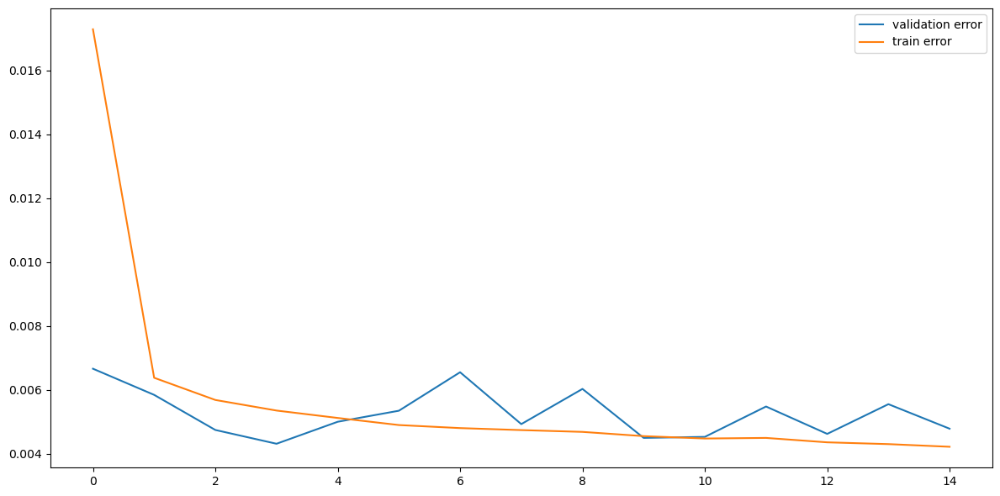

In [9]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-FI-reg-LOSS.pdf')
plt.show()

In [10]:
# load the best model (or the final one)
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/LSTM1-FI-best_model.pt', weights_only=False)

true = []
pred = []

torch.cuda.empty_cache()
# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = best_model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

# Plot each dimension separately
fig = make_subplots(rows=y_train.shape[1], cols=1)
for i in range(y_train.shape[1]):
    fig.add_scatter(y=true[:,i], mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(y=pred[:,i], mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {[shifts[i] for i in range(y_train.shape[1])]}", xaxis_title = "Time", yaxis_title = "Price", height=1600)
fig.write_html(f'./figures/{best_model.name}-FI-reg-pryce.html')
fig.show()

In [11]:
np.save(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.npy', true, pred)
torch.save(model.state_dict(), f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.pth')

for i in range(len(shifts)):
    print(utils.Metrics.sMAPE(true[:, i], pred[:, i]))
    print(r2_score(true[:, i], pred[:, i]))
    print(root_mean_squared_error(true[:, i], pred[:, i]))
    print()

8.071060478687286
0.9984296320259255
0.037006103

8.970658481121063
0.99771698583797
0.044600956

10.528804361820221
0.9967701789660001
0.053026315

12.940973043441772
0.9944690128228214
0.06932421



### LSTM with Attention mechanism

In [7]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [8]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'encoder_hidden_size': 64,
    'decoder_hidden_size': 64,
    'num_layers': 2,
    'output_size': y_train.shape[1],
    'dropout': 0.2
}
model = Models.LSTMWithAttention(**params).to(device)

# Define loss function and optimizer
learning_rate = 5*1e-4
epochs = 15
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = model.name,
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/15 [00:00<?, ?it/s]

model saved


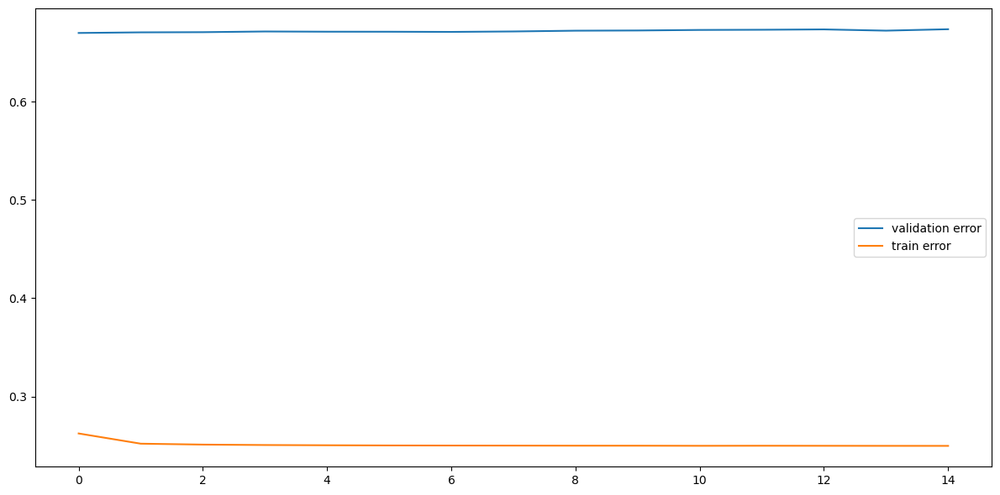

In [9]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-FI-reg-LOSS.pdf')
plt.show()

In [10]:
# load the best model (or the final one)
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/{model.name}-FI-best_model.pt', weights_only=False)

true = []
pred = []

# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = best_model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

# Plot each dimension separately
fig = make_subplots(rows=y_train.shape[1], cols=1)
for i in range(y_train.shape[1]):
    fig.add_scatter(y=true[:,i], mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(y=pred[:,i], mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {[shifts[i] for i in range(y_train.shape[1])]}", xaxis_title = "Time", yaxis_title = "Price", height=1600)
fig.write_html(f'./figures/{best_model.name}-FI-reg-pryce.html')
fig.show()

In [11]:
np.save(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.npy', true)
torch.save(model.state_dict(), f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.pth')

In [12]:
np.save(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.npy', true, pred)
torch.save(model.state_dict(), f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.pth')

for i in range(len(shifts)):
    print(utils.Metrics.sMAPE(true[:, i], pred[:, i]))
    print(r2_score(true[:, i], pred[:, i]))
    print(root_mean_squared_error(true[:, i], pred[:, i]))
    print()

200.0
-0.057741825083388765
0.9604228

12.018504738807678
0.994688188634939
0.068031676

13.051600754261017
0.9938420521555495
0.073218405

15.795163810253143
0.9901752753948032
0.092394



### Astice

In [13]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [14]:
# Create the model
params = {
    "input_size": X_train.shape[1],
    "output_size": y_train.shape[1],
    "hidden_size": 64,
    "lstm_size": 64,
    "lstm_layers": 2,
    "smooth_conv_channels": 32
}

model = Models.Astice(**params).to(device)

# Define loss function and optimizer
learning_rate = 5*1e-4
epochs = 15
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = model.name,
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/15 [00:00<?, ?it/s]

model saved
model saved
model saved


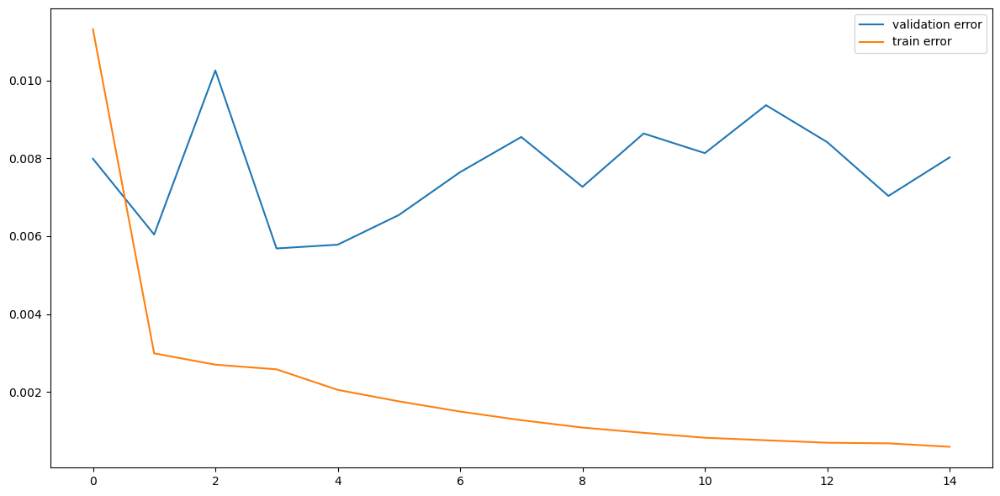

In [15]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-FI-reg-LOSS.pdf')
plt.show()

In [16]:
# load the best model (or the final one)
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/{model.name}-FI-best_model.pt', weights_only=False)

true = []
pred = []

# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = best_model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

# Plot each dimension separately
fig = make_subplots(rows=y_train.shape[1], cols=1)
for i in range(y_train.shape[1]):
    fig.add_scatter(y=true[:,i], mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(y=pred[:,i], mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {[shifts[i] for i in range(y_train.shape[1])]}", xaxis_title = "Time", yaxis_title = "Price", height=1600)
fig.write_html(f'./figures/{best_model.name}-FI-reg-pryce.html')
fig.show()

In [17]:
np.save(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.npy', true)
torch.save(model.state_dict(), f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.pth')

In [18]:
np.save(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.npy', true, pred)
torch.save(model.state_dict(), f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.pth')

for i in range(len(shifts)):
    print(utils.Metrics.sMAPE(true[:, i], pred[:, i]))
    print(r2_score(true[:, i], pred[:, i]))
    print(root_mean_squared_error(true[:, i], pred[:, i]))
    print()

7.9940952360630035
0.9984587529784982
0.036661375

9.521479904651642
0.9974931550505077
0.046736218

11.695456504821777
0.9958933936018984
0.059792098

14.318129420280457
0.9923502935220085
0.08152785



### LobCNN

In [12]:
# in this case the predicted pryce is P_Ask_1
dataset = pd.read_parquet('/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/Data/FI-2010-Cleaned/NoAuction/MinMax/WRT1V.parquet')
dataset = dataset.drop(['Label_10', 'Label_20', 'Label_30', 'Label_50', 'Label_100', 'Day'], axis=1)
dataset = dataset.astype(float)
dataset = dataset.head(100000)
display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,P_Bid_8,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10
0,0.962048,0.008123,0.964492,0.006633,0.962048,0.013564,0.964492,0.006650,0.961623,0.011154,...,0.964476,0.019060,0.956217,0.004534,0.964476,0.004935,0.955381,0.002298,0.964048,0.025081
1,0.961606,0.004041,0.964492,0.002583,0.961606,0.013564,0.964492,0.003317,0.961182,0.011154,...,0.965364,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785
2,0.961606,0.004041,0.964492,0.005917,0.961606,0.013564,0.964492,0.003317,0.961182,0.011154,...,0.965364,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785
3,0.961606,0.004041,0.964492,0.003117,0.961606,0.013564,0.964492,0.006650,0.961182,0.011154,...,0.965364,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785
4,0.961606,0.004041,0.964492,0.003117,0.961606,0.013564,0.964492,0.006650,0.961182,0.011154,...,0.965364,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,0.976876,0.028329,0.977615,0.019617,0.976876,0.027472,0.977208,0.004183,0.976876,0.005157,...,0.974766,0.004941,0.973769,0.004606,0.973545,0.031673,0.973769,0.010186,0.974338,0.003677
99996,0.976876,0.028329,0.977615,0.022950,0.976876,0.019612,0.977208,0.004183,0.976876,0.005157,...,0.976801,0.004397,0.973769,0.004606,0.975173,0.005180,0.973769,0.010186,0.974745,0.025127
99997,0.976876,0.028329,0.977615,0.024617,0.976876,0.019612,0.977208,0.004183,0.976876,0.005157,...,0.976801,0.004397,0.973769,0.004606,0.975173,0.005180,0.973769,0.010186,0.974745,0.025127
99998,0.976876,0.028329,0.977615,0.024617,0.976876,0.019612,0.977208,0.004183,0.976876,0.005157,...,0.974766,0.004941,0.973769,0.004606,0.973545,0.031673,0.973769,0.010186,0.974338,0.003677


In [13]:
target_col = 'P_Ask_1'
target_cols = []
shifts = [ 10, 20, 30, 50 ]

for shift in shifts:
    colname = f'Target_{shift}'
    target_cols.append(colname)
    dataset[colname] = dataset[target_col].shift(-shift)
dataset.dropna(inplace=True)

display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,Target_10,Target_20,Target_30,Target_50
0,0.962048,0.008123,0.964492,0.006633,0.962048,0.013564,0.964492,0.006650,0.961623,0.011154,...,0.964476,0.004935,0.955381,0.002298,0.964048,0.025081,0.962489,0.965137,0.964696,0.965578
1,0.961606,0.004041,0.964492,0.002583,0.961606,0.013564,0.964492,0.003317,0.961182,0.011154,...,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.962489,0.964254,0.964696,0.965578
2,0.961606,0.004041,0.964492,0.005917,0.961606,0.013564,0.964492,0.003317,0.961182,0.011154,...,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.962489,0.964254,0.964696,0.965578
3,0.961606,0.004041,0.964492,0.003117,0.961606,0.013564,0.964492,0.006650,0.961182,0.011154,...,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.962489,0.964254,0.964696,0.965578
4,0.961606,0.004041,0.964492,0.003117,0.961606,0.013564,0.964492,0.006650,0.961182,0.011154,...,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.962489,0.964254,0.964696,0.965578
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99945,0.976876,0.036656,0.976801,0.013033,0.976876,0.019612,0.976801,0.006067,0.976876,0.005157,...,0.971103,0.003693,0.973366,0.004372,0.971079,0.018658,0.976876,0.976876,0.976876,0.976876
99946,0.976876,0.036656,0.976801,0.013033,0.976876,0.019612,0.976801,0.006067,0.976876,0.005157,...,0.971103,0.003693,0.973366,0.004372,0.971079,0.018658,0.976876,0.976876,0.976876,0.976876
99947,0.976876,0.036656,0.976801,0.013033,0.976876,0.019612,0.976801,0.006067,0.976876,0.005157,...,0.971103,0.003693,0.973366,0.004372,0.971079,0.018658,0.976876,0.976876,0.976876,0.976876
99948,0.976876,0.036656,0.976801,0.013033,0.976876,0.019612,0.976801,0.006067,0.976876,0.005157,...,0.972324,0.031673,0.973366,0.004372,0.972301,0.002929,0.976876,0.976876,0.976876,0.976876


In [14]:
# Split the dataframe into train, validation and test
dataset_train, dataset_val, dataset_test = utils.DataTools.train_val_test_split(dataset)

# Standardize the data
#scaler = preprocessing.StandardScaler()
#scaler.fit(dataset_train)

#dataset_train[dataset_train.columns] = scaler.transform(dataset_train)
#dataset_val[dataset_val.columns] = scaler.transform(dataset_val)
#dataset_test[dataset_test.columns] = scaler.transform(dataset_test)

means = dataset_train.mean(axis=0)
stds = dataset_train.std(axis=0)

means[-len(target_cols):] = means[target_cols]
stds[-len(target_cols):] = stds[target_cols]

dataset_train = ( dataset_train - means ) / stds
dataset_val = ( dataset_val - means ) / stds
dataset_test = ( dataset_test - means ) / stds

display(dataset_train)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,Target_10,Target_20,Target_30,Target_50
0,-0.103889,-0.568377,-0.083299,-0.045714,-0.109612,-0.449853,-0.076871,-0.095413,-0.119712,-0.512333,...,-0.036927,-0.655496,-0.185019,-0.799781,-0.040749,0.932103,-0.092842,-0.027861,-0.038402,-0.016339
1,-0.114682,-0.768910,-0.083299,-0.617528,-0.120403,-0.449853,-0.076871,-0.568214,-0.130535,-0.512333,...,-0.026096,0.411836,-0.217769,1.647931,-0.019004,-0.594318,-0.092842,-0.049437,-0.038402,-0.016339
2,-0.114682,-0.768910,-0.083299,-0.146899,-0.120403,-0.449853,-0.076871,-0.568214,-0.130535,-0.512333,...,-0.026096,0.411836,-0.217769,1.647931,-0.019004,-0.594318,-0.092842,-0.049437,-0.038402,-0.016339
3,-0.114682,-0.768910,-0.083299,-0.542227,-0.120403,-0.449853,-0.076871,-0.095413,-0.130535,-0.512333,...,-0.026096,0.411836,-0.217769,1.647931,-0.019004,-0.594318,-0.092842,-0.049437,-0.038402,-0.016339
4,-0.114682,-0.768910,-0.083299,-0.542227,-0.120403,-0.449853,-0.076871,-0.095413,-0.130535,-0.512333,...,-0.026096,0.411836,-0.217769,1.647931,-0.019004,-0.594318,-0.092842,-0.049437,-0.038402,-0.016339
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69960,-1.750607,0.364103,-1.764441,-0.297500,-1.755932,-0.642231,-1.758128,0.850189,-1.761294,-0.646372,...,-1.787001,-0.840058,-1.796870,1.403194,-1.779930,-0.741223,-1.739977,-1.709337,-1.708743,-1.727547
69961,-1.750607,0.765170,-1.774531,0.897896,-1.755932,-0.642231,-1.768219,-0.095413,-1.761294,-0.646372,...,-1.807051,-0.754450,-1.776532,-0.641452,-1.810159,-0.807761,-1.739977,-1.709337,-1.708743,-1.727547
69962,-1.750607,-0.167310,-1.774531,0.897896,-1.755932,-0.642231,-1.768219,-0.095413,-1.761294,-0.646372,...,-1.787001,-0.840058,-1.776532,-0.641452,-1.779930,-0.741223,-1.739977,-1.709337,-1.708743,-1.727547
69963,-1.750607,-0.568377,-1.774531,0.897896,-1.755932,-0.642231,-1.768219,-0.095413,-1.761294,-0.646372,...,-1.787001,-0.840058,-1.776532,-0.641452,-1.779930,-0.741223,-1.739977,-1.709337,-1.708743,-1.727547


In [15]:
# Split covariates and response variables
X_train, y_train = utils.DataTools.split_x_y(dataset_train, target_cols)
X_val, y_val = utils.DataTools.split_x_y(dataset_val, target_cols)
X_test, y_test = utils.DataTools.split_x_y(dataset_test, target_cols)

# Convert to pytorch tensors
X_train, X_val, X_test = utils.DataTools.numpy_to_tensor( X_train, X_val, X_test, dtype=torch.float32 )
y_train, y_val, y_test = utils.DataTools.numpy_to_tensor( y_train, y_val, y_test, dtype=torch.float32 )

# Create Torch Dataset
lookback_period = 100
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = True,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = True,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = True,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)

# Create Torch DataLoader
batch_size = 32
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = batch_size,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = batch_size,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 1024,
    shuffle = False
)

print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 69766 samples
Test dataset: 14794 samples


In [16]:
dataloader_train.dataset.channels = True
dataloader_val.dataset.channels = True
dataloader_test.dataset.channels = True

In [17]:
# Create the model

params = {
    "vertical_convolutional_layers" : 2,
    "vertical_kernel_size" : 4,
    "smoothing" : False,
    "convolution_channels" : 32,
    "inception_channels" : 64,
    "lstm_layers" : 2,
    "latent_size" : 128,
    "dropout" : 0.1,
    "output_size" : y_train.shape[1],
}

model = Models.LobCNN(**params).to(device)

# Define loss function and optimizer
learning_rate = 5*1e-4
epochs = 15
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = model.name,
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/15 [00:00<?, ?it/s]

/home/joel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/conv.py:454: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /opt/conda/conda-bld/pytorch_1720538455419/work/aten/src/ATen/native/Convolution.cpp:1031.)
  return F.conv2d(input, weight, bias, self.stride,


model saved
model saved
model saved
model saved
model saved


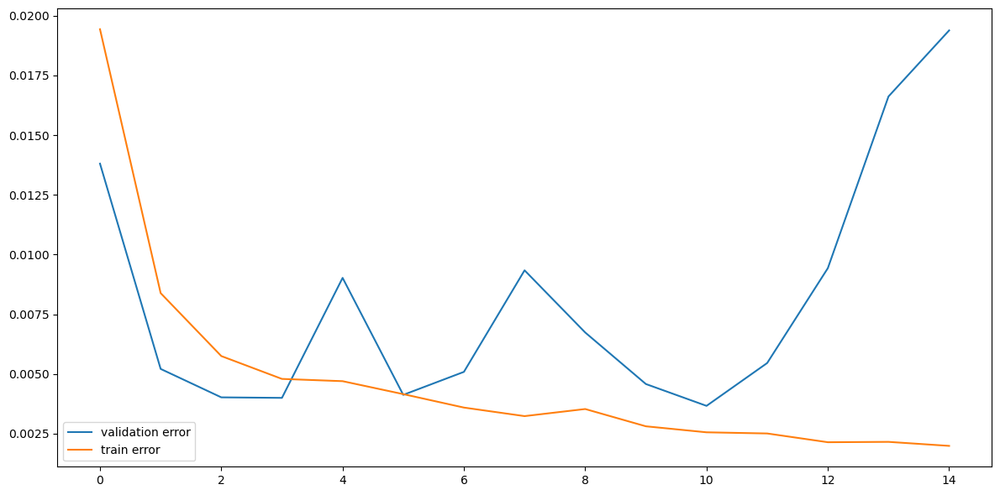

In [18]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-FI-reg-LOSS.pdf')
plt.show()

In [21]:
# load the best model (or the final one)
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/{model.name}-FI-best_model.pt', weights_only=False)

true = []
pred = []

# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = best_model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

# Plot each dimension separately
fig = make_subplots(rows=y_train.shape[1], cols=1)
for i in range(y_train.shape[1]):
    fig.add_scatter(y=true[:,i], mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(y=pred[:,i], mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {[shifts[i] for i in range(y_train.shape[1])]}", xaxis_title = "Time", yaxis_title = "Price", height=1600)
fig.write_html(f'./figures/{best_model.name}-FI-reg-pryce.html')
fig.show()

In [20]:
np.save(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.npy', true)
torch.save(model.state_dict(), f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.pth')

In [22]:
np.save(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.npy', true, pred)
torch.save(model.state_dict(), f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-FI-reg.pth')

for i in range(len(shifts)):
    print(utils.Metrics.sMAPE(true[:, i], pred[:, i]))
    print(r2_score(true[:, i], pred[:, i]))
    print(root_mean_squared_error(true[:, i], pred[:, i]))
    print()

14.77607786655426
0.9853679294624501
0.06432838

15.686708688735962
0.9840278109990478
0.067181274

16.78846627473831
0.9817468192560184
0.07178545

19.168993830680847
0.9763461300833244
0.08163416



### LSTM seq-to-seq with Attention

In [23]:
dataset = pd.read_parquet('/home/joel/Desktop/DSSC/DEEP_LEARNING/Data/FI-2010/NoAuction/MinMax/WRT1V.parquet')
dataset = dataset.astype(float)
dataset = dataset.drop(['Label_10', 'Label_20', 'Label_30', 'Label_50', 'Label_100', 'Day'], axis=1)
dataset['mid_price'] = (dataset['P_Ask_1'] + dataset['P_Bid_1']) / 2
#dataset = dataset.head(100000)
display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price
0,0.962048,0.008123,0.964492,0.006633,0.962048,0.013564,0.964492,0.006650,0.961623,0.011154,...,0.019060,0.956217,0.004534,0.964476,0.004935,0.955381,0.002298,0.964048,0.025081,0.963270
1,0.961606,0.004041,0.964492,0.002583,0.961606,0.013564,0.964492,0.003317,0.961182,0.011154,...,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049
2,0.961606,0.004041,0.964492,0.005917,0.961606,0.013564,0.964492,0.003317,0.961182,0.011154,...,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049
3,0.961606,0.004041,0.964492,0.003117,0.961606,0.013564,0.964492,0.006650,0.961182,0.011154,...,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049
4,0.961606,0.004041,0.964492,0.003117,0.961606,0.013564,0.964492,0.006650,0.961182,0.011154,...,0.009819,0.954466,0.005049,0.964920,0.019060,0.954068,0.044282,0.964936,0.004785,0.963049
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147150,1.044112,0.046126,1.046653,0.014600,1.044112,0.030420,1.046285,0.006867,1.043267,0.041089,...,0.004232,1.040742,0.010879,1.045085,0.035812,1.039484,0.007837,1.045085,0.023751,1.045382
147151,1.044112,0.046126,1.046653,0.014600,1.044112,0.030420,1.046285,0.005200,1.043267,0.041089,...,0.004232,1.040742,0.010879,1.045085,0.035812,1.039484,0.007837,1.045085,0.023751,1.045382
147152,1.044112,0.046126,1.046653,0.014600,1.044112,0.030420,1.046285,0.003533,1.043267,0.041089,...,0.012057,1.040742,0.010879,1.045898,0.004436,1.039484,0.007837,1.045492,0.028410,1.045382
147153,1.044112,0.046126,1.046653,0.014600,1.044112,0.030420,1.046691,0.001650,1.043267,0.041089,...,0.012057,1.040742,0.010879,1.045898,0.004436,1.039484,0.007837,1.045492,0.028410,1.045382


In [24]:
# Split the dataframe into train, validation and test
dataset_train, dataset_val, dataset_test = utils.DataTools.train_val_test_split(dataset)

# Standardize the data
scaler = preprocessing.StandardScaler()
scaler.fit(dataset_train)

dataset_train[dataset_train.columns] = scaler.fit_transform(dataset_train)
dataset_val[dataset_val.columns] = scaler.fit_transform(dataset_val)
dataset_test[dataset_test.columns] = scaler.fit_transform(dataset_test)

display(dataset_train)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price
0,0.167830,-0.565847,0.192601,-0.027253,0.162610,-0.391088,0.198238,-0.077008,0.151848,-0.440418,...,0.470092,0.106494,-0.628433,0.238798,-0.613380,0.083921,-0.768334,0.233120,0.993520,0.180261
1,0.157060,-0.758829,0.192601,-0.617827,0.151847,-0.391088,0.198238,-0.568830,0.141056,-0.440418,...,-0.270765,0.063560,-0.593387,0.249570,0.431894,0.051285,1.810822,0.254758,-0.551552,0.174877
2,0.157060,-0.758829,0.192601,-0.131758,0.151847,-0.391088,0.198238,-0.568830,0.141056,-0.440418,...,-0.270765,0.063560,-0.593387,0.249570,0.431894,0.051285,1.810822,0.254758,-0.551552,0.174877
3,0.157060,-0.758829,0.192601,-0.540056,0.151847,-0.391088,0.198238,-0.077008,0.141056,-0.440418,...,-0.270765,0.063560,-0.593387,0.249570,0.431894,0.051285,1.810822,0.254758,-0.551552,0.174877
4,0.157060,-0.758829,0.192601,-0.540056,0.151847,-0.391088,0.198238,-0.077008,0.141056,-0.440418,...,-0.270765,0.063560,-0.593387,0.249570,0.431894,0.051285,1.810822,0.254758,-0.551552,0.174877
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103003,0.668287,2.757305,0.661546,-0.880304,0.662792,0.027096,0.667440,0.166444,0.663984,-0.797677,...,-0.529206,0.675304,-0.656899,0.626615,-0.663125,0.681730,-0.642350,0.642813,-0.872371,0.665070
103004,0.648488,-0.156724,0.651620,0.215781,0.643003,-0.397099,0.657508,0.606625,0.644133,0.077673,...,-0.732025,0.615943,-0.338257,0.606870,-0.925388,0.631550,2.104857,0.632884,-0.608954,0.650206
103005,0.648488,-0.156724,0.651620,0.215781,0.643003,-0.397099,0.657508,0.606625,0.644133,0.221173,...,-0.732025,0.615943,-0.338257,0.606870,-0.925388,0.631550,2.104857,0.632884,-0.608954,0.650206
103006,0.648488,-0.156724,0.651620,0.215781,0.643003,-0.250825,0.657508,0.606625,0.644133,0.221173,...,-0.732025,0.615943,-0.338257,0.606870,-0.925388,0.631550,2.104857,0.632884,-0.608954,0.650206


In [25]:
# Split covariates and response variables
X_train, y_train = utils.DataTools.split_x_y(dataset_train, ['mid_price'])
X_val, y_val = utils.DataTools.split_x_y(dataset_val, ['mid_price'])
X_test, y_test = utils.DataTools.split_x_y(dataset_test, ['mid_price'])

# Convert to pytorch tensors
X_train, X_val, X_test = utils.DataTools.numpy_to_tensor( X_train, X_val, X_test, dtype=torch.float32 )
y_train, y_val, y_test = utils.DataTools.numpy_to_tensor( y_train, y_val, y_test, dtype=torch.float32 )

# Create Torch Dataset
lookback_period = 100
seq_len_y = 51
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = lookback_period,
    seq_len_y = seq_len_y,
    offset    = lookback_period,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = lookback_period,
    seq_len_y = seq_len_y,
    offset    = lookback_period,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = lookback_period,
    seq_len_y = seq_len_y,
    offset    = lookback_period,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)

# Create Torch DataLoader
batch_size = 32
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = batch_size,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = batch_size,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 1024,
    shuffle = False
)

#display(pd.DataFrame(dataset_train[9][0]))
#display(pd.DataFrame(dataset_train[9][1]))
#display(pd.DataFrame(dataset_train[10][0]))
#display(pd.DataFrame(dataset_train[10][1]))
#display(pd.DataFrame(dataset_train[11][0]))
#display(pd.DataFrame(dataset_train[11][1]))

print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 102808 samples
Test dataset: 21874 samples


In [26]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [27]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'output_size': y_train.shape[1],
    'encoder_hidden_size': 64,
    'decoder_hidden_size': 64,
    'num_layers': 2,
    'dropout': 0.2
}

model = Models.LSTMSeq2SeqAttention(**params).to(device)

# Define loss function and optimizer
learning_rate = 5*1e-4
epochs = 15
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train_seq_to_seq(
    model_id = model.name,
    model = model,
    teacher_forcing_ratio = 0.5,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/15 [00:00<?, ?it/s]

model saved


KeyboardInterrupt: 

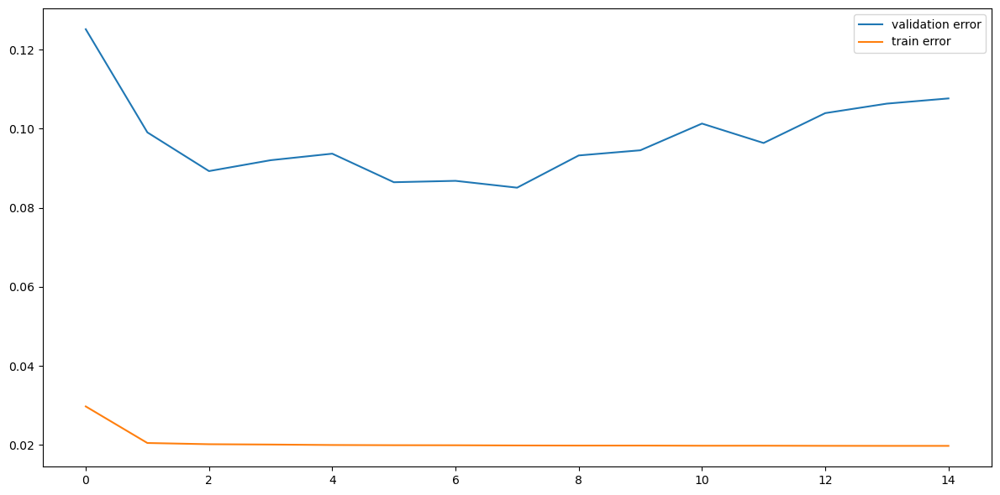

In [ ]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-FI-reg-LOSS.pdf')
plt.show()

In [ ]:
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/{model.name}-FI-best_model.pt', weights_only=False)

shifts = [ 1, 10, 20, 50 ]

fig = make_subplots(rows=len(shifts), cols=1)

# Evaluate the model
for i in range(len(shifts)):
    true = []
    pred = []
    with torch.no_grad():
        for inputs, labels in dataloader_test:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = best_model(inputs, labels, teacher_forcing_ratio=0.)
            true.append(labels[:,shifts[i],:].cpu().numpy())
            pred.append(outputs[:,shifts[i],:].cpu().numpy())
    
    true = np.concatenate(true)#.reshape(-1, y_train.shape[1])
    pred = np.concatenate(pred)#.reshape(-1, y_train.shape[1])
    
    fig.add_scatter(x=np.arange(len(true)), y=true.flatten(), mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(x=np.arange(len(pred)), y=pred.flatten(), mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {shifts}", xaxis_title = "Time", yaxis_title = "Price", height=1600)

fig.write_html(f'./figures/{best_model.name}-FI-reg-pryce.html')
fig.show()

### lobCNN seq-to-seq with Attention

In [ ]:
dataloader_train.dataset.channels = True
dataloader_val.dataset.channels = True
dataloader_test.dataset.channels = True

In [ ]:
# Create the model
params = {
    'vertical_convolutional_layers' : 2,
    'vertical_kernel_size' : 4,
    'smoothing' : False,
    'convolution_channels' : 32,
    'inception_channels' : 64,
    'lstm_layers' : 2,
    'encoder_hidden_size' : 64,
    'decoder_hidden_size' : 64,
    'dropout' : 0.2,
    'output_size' : y_train.shape[1],
}

model = Models.LobCNN_seq2seq_Attention(**params).to(device)

# Define loss function and optimizer
learning_rate = 5*1e-4
epochs = 15
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train_seq_to_seq(
    model_id = model.name,
    model = model,
    teacher_forcing_ratio = 0.5,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/15 [00:00<?, ?it/s]

torch.Size([32, 100, 256])


/home/joel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/conv.py:454: UserWarning:

Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /opt/conda/conda-bld/pytorch_1720538455419/work/aten/src/ATen/native/Convolution.cpp:1031.)



RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

In [ ]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-FI-reg-LOSS.pdf')
plt.show()

In [ ]:
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/{model.name}-FI-best_model.pt', weights_only=False)

shifts = [ 1, 10, 20, 49 ]

fig = make_subplots(rows=len(shifts), cols=1)

# Evaluate the model
for i in range(len(shifts)):
    true = []
    pred = []
    with torch.no_grad():
        for inputs, labels in dataloader_test:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = best_model(inputs, labels, teacher_forcing_ratio=0.)
            true.append(labels[:,shifts[i],:].cpu().numpy())
            pred.append(outputs[:,shifts[i],:].cpu().numpy())
    
    true = np.concatenate(true)#.reshape(-1, y_train.shape[1])
    pred = np.concatenate(pred)#.reshape(-1, y_train.shape[1])
    
    fig.add_scatter(x=np.arange(len(true)), y=true.flatten(), mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(x=np.arange(len(pred)), y=pred.flatten(), mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {shifts}", xaxis_title = "Time", yaxis_title = "Price", height=1600)

fig.write_html(f'./figures/{best_model.name}-FI-reg-pryce.html')
fig.show()